# YouTube Trending Videos: Views and Engagement

This notebook explores **161,470 YouTube trending records** from the **US, Canada, France, and GB**, collected between **November 14, 2017 and June 14, 2018**.

We check the data quality, clean it, and then look at how **views** relate to **likes**, **comments**, and **publish dates**. The results describe patterns in this dataset only. They do not prove what makes a video trend.

## Problem statement

From November 14, 2017 to June 14, 2018, 161,470 YouTube trending records across four countries show view counts from 223 to about 424.5 million. The relationship between views and likes or comments is unclear, making it difficult to describe engagement among videos that reached the trending lists.

### SMART criteria

| Criteria | How this project meets it |
| --- | --- |
| **Specific** | Views and their relationship with likes and comments in the four-country dataset. |
| **Measurable** | The direction and strength of each relationship, using correlation and engagement rates (likes and comments per 100 views). |
| **Achievable** | The dataset has all three measures. Repeated records, broken IDs, and disabled comments or ratings are handled. |
| **Relevant** | The results describe engagement among videos on these trending lists. |
| **Time-bound** | Data from November 14, 2017 to June 14, 2018. Analysis completed by the course submission date. |

### Scope

- **In scope:** `views` as the main variable, compared with `likes`, `comment_count`, and publish timing. One record per video per country.
- **Out of scope:** What causes a video to trend, all YouTube videos in general, and category or tags.

## Table of contents

1. [Problem statement](#problem-statement)
2. [Part 1: Import libraries](#part-1-import-libraries)
3. [Part 2: View the data](#part-2-view-the-data)
4. [Part 3: Check data quality](#part-3-check-data-quality)
5. [Part 4: Clean the data](#part-4-clean-the-data)
6. [Part 5: Views, likes, and comments](#part-5-views-likes-and-comments)
7. [Part 6: Publish dates](#part-6-publish-dates)
8. [Part 7: Summary and recommendations](#part-7-summary-and-recommendations)

## Part 1: Import libraries

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

## Part 2: View the data

Load the file and get a first look: how big it is, what columns it has, and what the numbers look like.

#### 1. Load the CSV file

In [46]:
youtube_df = pd.read_csv('data/youtube.csv')

#### 2. Check the number of rows and columns

In [47]:
youtube_df.shape

(161470, 18)

#### 3. Preview the first five rows

In [48]:
youtube_df.head(5)

,index,video_id,trending_date,title,channel_title,category_id,publish_date,time_frame,published_day_of_week,publish_country,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed
0,0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,13/11/2017,17:00 to 17:59,Monday,US,SHANtell martin,748374,57527,2966,15954,False,False,False
1,1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,13/11/2017,7:00 to 7:59,Monday,US,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,False,False,False
2,2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,12/11/2017,19:00 to 19:59,Sunday,US,"racist superman|""rudy""""|""""mancuso""""|""""king""""|""...",3191434,146033,5339,8181,False,False,False
3,3,puqaWrEC7tY,17.14.11,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,13/11/2017,11:00 to 11:59,Monday,US,"rhett and link|""gmm""""|""""good mythical morning""...",343168,10172,666,2146,False,False,False
4,4,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,12/11/2017,18:00 to 18:59,Sunday,US,"ryan|""higa""""|""""higatv""""|""""nigahiga""""|""""i dare ...",2095731,132235,1989,17518,False,False,False


#### 4. Check the columns and data types

In [49]:
youtube_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 161470 entries, 0 to 161469
Data columns (total 18 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   index                   161470 non-null  int64
 1   video_id                161470 non-null  str  
 2   trending_date           161470 non-null  str  
 3   title                   161470 non-null  str  
 4   channel_title           161470 non-null  str  
 5   category_id             161470 non-null  int64
 6   publish_date            161470 non-null  str  
 7   time_frame              161470 non-null  str  
 8   published_day_of_week   161470 non-null  str  
 9   publish_country         161470 non-null  str  
 10  tags                    161470 non-null  str  
 11  views                   161470 non-null  int64
 12  likes                   161470 non-null  int64
 13  dislikes                161470 non-null  int64
 14  comment_count           161470 non-null  int64
 15  comments_di

#### 5. View each column data type

In [50]:
youtube_df.dtypes

index                     int64
video_id                    str
trending_date               str
title                       str
channel_title               str
category_id               int64
publish_date                str
time_frame                  str
published_day_of_week       str
publish_country             str
tags                        str
views                     int64
likes                     int64
dislikes                  int64
comment_count             int64
comments_disabled          bool
ratings_disabled           bool
video_error_or_removed     bool
dtype: object

#### 6. Basic statistics

`describe()` gives the count, average (mean), minimum, maximum, and quartiles for each number column. `astype(int)` drops the decimals so the table is easier to read.

In [51]:
youtube_df[['views', 'likes', 'dislikes', 'comment_count']].describe().astype(int)

,views,likes,dislikes,comment_count
count,161470,161470,161470,161470
mean,2419854,65661,3490,7035
std,10437486,226061,31147,34041
min,223,0,0,0
25%,101538,1975,85,279
50%,384739,9840,348,1144
75%,1339528,40062,1350,4144
max,424538912,5613827,1944971,1626501


The **average** video has about **2.4 million** views, but the **median** is only about **385,000**. A small number of very popular videos pull the average up, so the median is a better picture of a typical video.

Note that the same video appears many times here, once for every day it trends. We fix this in Part 4.

## Part 3: Check data quality

Before analysing, we look for problems: missing values, repeated rows, broken video IDs, and videos with comments or ratings turned off.

> `#NAME?` is a broken video ID (an Excel error), not a missing value, so it will not show up in the missing-value count.

#### 1. Count missing values in each column

In [52]:
youtube_df.isnull().sum()

index                     0
video_id                  0
trending_date             0
title                     0
channel_title             0
category_id               0
publish_date              0
time_frame                0
published_day_of_week     0
publish_country           0
tags                      0
views                     0
likes                     0
dislikes                  0
comment_count             0
comments_disabled         0
ratings_disabled          0
video_error_or_removed    0
dtype: int64

#### 2. Check the percentage of missing values

In [53]:
(youtube_df.isnull().mean() * 100).round(2)

index                     0.0
video_id                  0.0
trending_date             0.0
title                     0.0
channel_title             0.0
category_id               0.0
publish_date              0.0
time_frame                0.0
published_day_of_week     0.0
publish_country           0.0
tags                      0.0
views                     0.0
likes                     0.0
dislikes                  0.0
comment_count             0.0
comments_disabled         0.0
ratings_disabled          0.0
video_error_or_removed    0.0
dtype: float64

Every column shows **0% missing**, so no rows need to be dropped for missing values.

#### 3. Check duplicate rows

In [54]:
youtube_df.drop(columns='index').duplicated().sum()

np.int64(219)

**219 rows (0.14%)** are exact copies of another row (ignoring the `index` column). We will drop them so no record is counted twice.

#### 4. Count unusable video IDs

In [55]:
(youtube_df['video_id'] == '#NAME?').sum()

np.int64(1799)

**1,799 rows (1.11%)** have `#NAME?` instead of a real video ID. We will drop them because we cannot tell which video they belong to.

Together with the duplicates, this removes **2,016 rows (1.25%)**. Two rows are in both groups, which is why the total is not 2,018.

#### 5. Count rows with comments disabled

In [56]:
youtube_df['comments_disabled'].sum()

np.int64(2788)

#### 6. Count rows with ratings disabled

In [57]:
youtube_df['ratings_disabled'].sum()

np.int64(1424)

#### 7. Count rows flagged as video error or removed

In [58]:
youtube_df['video_error_or_removed'].sum()

np.int64(141)

- **Comments disabled:** 2,788 rows (1.73%)
- **Ratings disabled:** 1,424 rows (0.88%)
- **Error or removed:** 141 rows (0.09%)

When comments or ratings are turned off, the count shows 0. That is not the same as nobody liking or commenting, so we keep these rows for views but leave them out when comparing likes and comments. The 141 error rows still have their counts, so we keep them.

#### 8. Visualize missing values

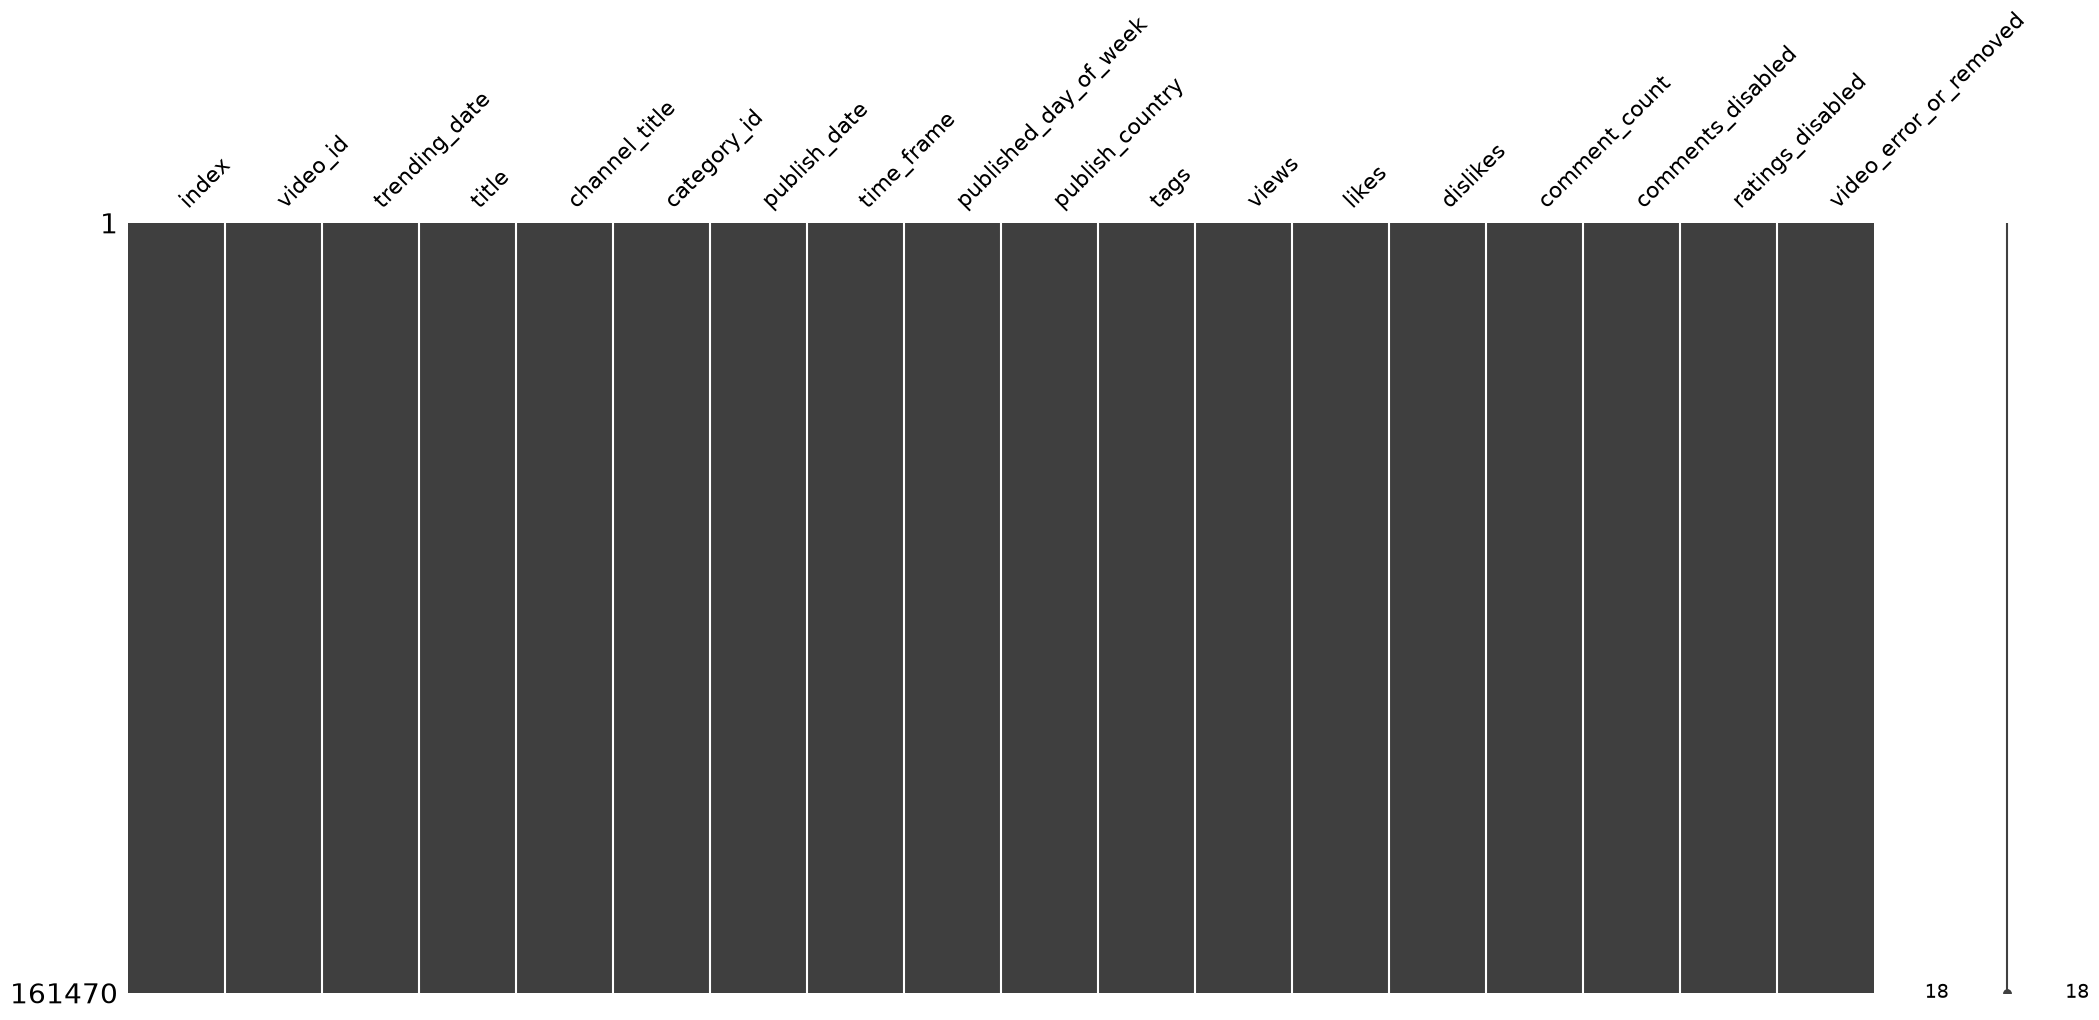

In [59]:
msno.matrix(youtube_df)
plt.show()

## Part 4: Clean the data

We make a working copy called `newyoutube_df`, remove the duplicates and broken IDs, fix the date columns, and keep only the **first trending day** for each video in each country.

#### 1. Create a working dataframe without the row index

In [60]:
newyoutube_df = youtube_df.drop(columns='index')
newyoutube_df.shape

(161470, 17)

#### 2. Remove exact duplicate rows

In [61]:
newyoutube_df = newyoutube_df.drop_duplicates()
newyoutube_df.shape

(161251, 17)

#### 3. Remove rows with an unusable video ID

In [62]:
newyoutube_df = newyoutube_df[newyoutube_df['video_id'] != '#NAME?']
newyoutube_df.shape

(159454, 17)

#### 4. Count how many rows were removed in total

In [63]:
len(youtube_df) - len(newyoutube_df)

2016

#### 5. Convert the date columns to datetime

The two date columns use unusual formats, so the simple `astype('datetime64[ns]')` does not work:

| Column | Format in the file | Example | Problem with `astype` |
| --- | --- | --- | --- |
| `trending_date` | year.day.month | `17.14.11` | Fails with "month must be in 1..12" |
| `publish_date` | day/month/year | `13/11/2017` | Reads `12/11/2017` as 11 December instead of 12 November |

So we use `pd.to_datetime` with `format=` to tell pandas the right order: `%y` = 2-digit year, `%Y` = 4-digit year, `%d` = day, `%m` = month.

In [64]:
newyoutube_df['trending_date'] = pd.to_datetime(newyoutube_df['trending_date'], format='%y.%d.%m')

In [65]:
newyoutube_df['publish_date'] = pd.to_datetime(newyoutube_df['publish_date'], format='%d/%m/%Y')

In [66]:
newyoutube_df[['trending_date', 'publish_date']].dtypes

trending_date    datetime64[us]
publish_date     datetime64[us]
dtype: object

#### 6. Check the trending date range

In [67]:
newyoutube_df['trending_date'].min(), newyoutube_df['trending_date'].max()

(Timestamp('2017-11-14 00:00:00'), Timestamp('2018-06-14 00:00:00'))

#### 7. Count how many different trending dates we have

In [68]:
newyoutube_df['trending_date'].nunique()

205

The period from November 14, 2017 to June 14, 2018 has **213 days**, but we only have **205 trending dates**. The missing days are **January 10 to 11** and **April 8 to 13, 2018**. We need to keep this gap in mind in Part 6.

#### 8. Keep the first trending record for each video in each country

A video appears once for every day it stays on the trending list. Keeping only its first day stops popular videos from being counted many times. The file is already sorted by trending date, so `keep='first'` keeps the earliest record.

In [69]:
newyoutube_df = newyoutube_df.drop_duplicates(subset=['video_id', 'publish_country'], keep='first')
newyoutube_df.shape

(63801, 17)

#### 9. Describe the clean table

In [70]:
newyoutube_df[['views', 'likes', 'comment_count']].describe().astype(int)

,views,likes,comment_count
count,63801,63801,63801
mean,436533,17575,2264
std,1476190,75665,12649
min,274,0,0
25%,31250,545,91
50%,124496,2727,408
75%,378990,10822,1392
max,143408235,3880074,733373


We now have **63,801 records**, one per video per country. On its first trending day, the median video had about:

- **124,500** views
- **2,700** likes
- **400** comments

## Part 5: Views, likes, and comments

This part answers the main question: **how do views relate to likes and comments?**

#### 1. Keep rows where likes and comments are turned on

If ratings or comments are disabled, the count shows 0 even though people could not like or comment. Leaving these rows out keeps the comparison fair.

In [71]:
engagement_df = newyoutube_df[(newyoutube_df['ratings_disabled'] == False) & (newyoutube_df['comments_disabled'] == False)]
engagement_df.shape

(62155, 17)

#### 2. Distribution of views

We divide views by 1,000 so the axis shows thousands instead of scientific notation like `1e8`.

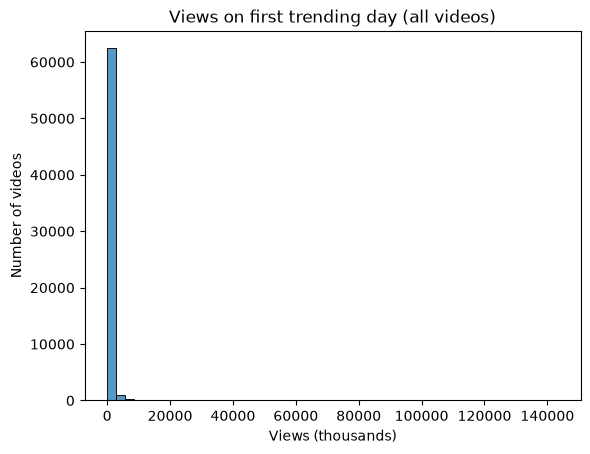

In [72]:
sns.histplot(x=newyoutube_df['views'] / 1000, bins=50)
plt.title('Views on first trending day (all videos)')
plt.xlabel('Views (thousands)')
plt.ylabel('Number of videos')
plt.show()

Almost all videos fall in the first bar, while a few reach very high views (up to about **143 million**). These huge videos squash the chart, so next we zoom in on videos under 1 million views.

In [73]:
under_1m_df = newyoutube_df[newyoutube_df['views'] < 1000000]
len(under_1m_df) / len(newyoutube_df)

0.9054560273349948

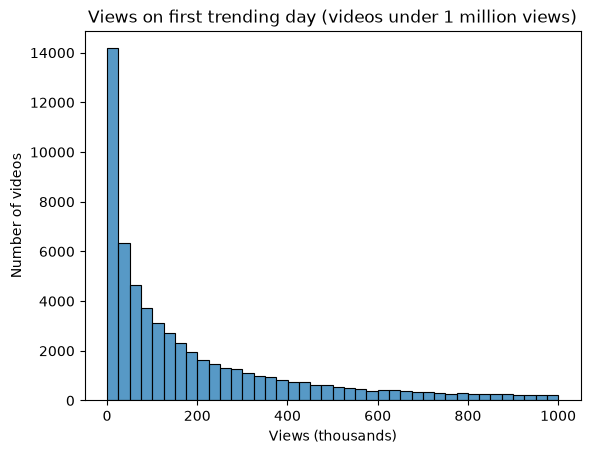

In [74]:
sns.histplot(x=under_1m_df['views'] / 1000, bins=40)
plt.title('Views on first trending day (videos under 1 million views)')
plt.xlabel('Views (thousands)')
plt.ylabel('Number of videos')
plt.savefig('charts/views_under_1m.png', bbox_inches='tight')
plt.show()

About **91%** of videos had under 1 million views. Even in this group, most videos sit on the left and the number drops as views go up. So a video does **not** need millions of views to reach the trending list.

#### 3. Correlation heatmap

Correlation is a number between -1 and 1. **Close to 1** means two columns go up together. **Close to 0** means there is little relationship. `annot=True` writes the number in each square.

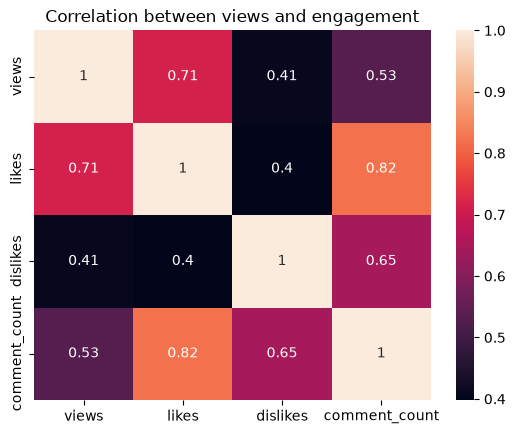

In [75]:
sns.heatmap(engagement_df[['views', 'likes', 'dislikes', 'comment_count']].corr(), annot=True)
plt.title('Correlation between views and engagement')
plt.savefig('charts/correlation_heatmap.png', bbox_inches='tight')
plt.show()

| Pair | Correlation | What it means |
| --- | --- | --- |
| Views and likes | **0.71** | Fairly strong. More views usually means more likes. |
| Views and comments | **0.53** | Weaker. Comments are less predictable than likes. |
| Likes and comments | **0.82** | Strong. Videos with many likes usually get many comments too. |
| Views and dislikes | **0.41** | The weakest link. |

This answers the problem statement: **likes follow views more closely than comments do.** These are relationships, not proof that one causes the other.

#### 4. Likes and comments per 100 views

Bigger videos naturally get more likes. Dividing by views lets us compare small and large videos fairly.

In [76]:
engagement_df['likes_per_100_views'] = engagement_df['likes'] / engagement_df['views'] * 100
engagement_df['comments_per_100_views'] = engagement_df['comment_count'] / engagement_df['views'] * 100
engagement_df[['likes_per_100_views', 'comments_per_100_views']].describe().round(2)

,likes_per_100_views,comments_per_100_views
count,62155.00,62155.00
mean,4.06,0.65
std,3.97,0.97
min,0.00,0.00
25%,0.94,0.16
50%,2.75,0.38
75%,6.08,0.78
max,49.48,32.34


A typical (median) trending video got about **2.75 likes** and **0.38 comments** for every 100 views. The middle half of videos got between about **0.9 and 6.1 likes** per 100 views. We use these numbers again in the recommendations.

#### 5. Compare countries

First, check how many videos each country has, then compare their median views.

In [77]:
newyoutube_df['publish_country'].value_counts()

publish_country
FRANCE    30181
CANADA    24103
US         6281
GB         3236
Name: count, dtype: int64

In [78]:
country_views = newyoutube_df.groupby('publish_country')['views'].median().sort_values()
country_views

publish_country
FRANCE     44874.0
CANADA    220610.0
US        271281.0
GB        279472.0
Name: views, dtype: float64

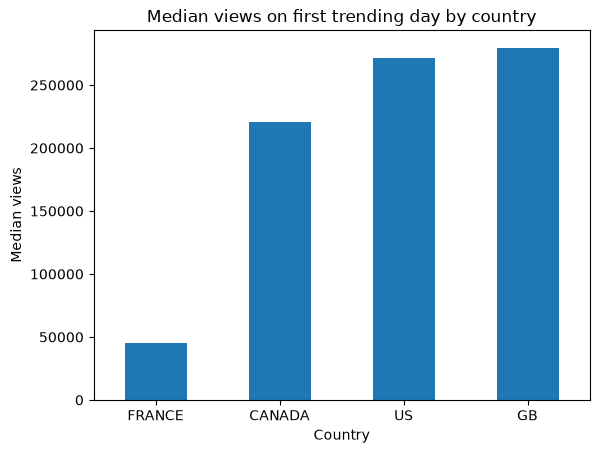

In [79]:
country_views.plot(kind='bar', rot=0)
plt.title('Median views on first trending day by country')
plt.xlabel('Country')
plt.ylabel('Median views')
plt.savefig('charts/median_views_by_country.png', bbox_inches='tight')
plt.show()

- **France** has the most videos (**30,181**) but the lowest median views (about **45,000**).
- **Canada, the US, and GB** sit between about **220,000 and 280,000**.

GB and the US have fewer different videos because their videos stay on the trending list for more days. France makes up almost half the table, so it pulls the overall median down.

## Part 6: Publish dates

Here we use `publish_date` to see if publish timing shows any pattern with views. These are observations only. A date by itself does not cause more or fewer views.

#### 1. How many days from publishing to trending?

Subtracting two dates gives a time difference. `.dt.days` turns it into a whole number of days.

In [80]:
newyoutube_df['days_to_trend'] = (newyoutube_df['trending_date'] - newyoutube_df['publish_date']).dt.days
newyoutube_df['days_to_trend'].value_counts().sort_index().head(8)

days_to_trend
0     3121
1    49047
2     7237
3     1552
4      762
5      486
6      286
7      194
Name: count, dtype: int64

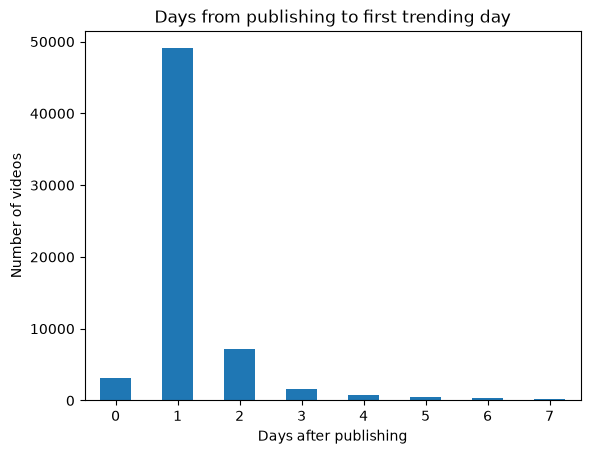

In [81]:
newyoutube_df['days_to_trend'].value_counts().sort_index().head(8).plot(kind='bar', rot=0)
plt.title('Days from publishing to first trending day')
plt.xlabel('Days after publishing')
plt.ylabel('Number of videos')
plt.savefig('charts/days_to_trend.png', bbox_inches='tight')
plt.show()

Most videos (**49,047 of 63,801, about 77%**) first trended **one day** after they were published. Another **3,121** trended the same day. So the views, likes, and comments we compare are mostly from a video's first day or two.

#### 2. Keep videos published during the data period

Some videos were published years earlier (the oldest is from 2006). We keep videos published from November 14, 2017 so the date charts are readable.

In [82]:
recent_df = newyoutube_df[newyoutube_df['publish_date'] >= '2017-11-14']
recent_df.shape

(62592, 18)

#### 3. Count videos and median views for each publish date

In [83]:
daily_df = recent_df.groupby('publish_date')['views'].agg(['count', 'median'])
daily_df.head()

,count,median
publish_date,,
2017-11-14,320,97823.0
2017-11-15,402,108456.0
2017-11-16,319,122728.0
2017-11-17,329,114688.0
2017-11-18,260,125742.5


#### 4. Find the dates with the most published videos

In [84]:
daily_df.sort_values('count', ascending=False).head(5)

,count,median
publish_date,,
2018-01-29,457,100486.0
2018-02-15,448,68439.5
2018-05-13,435,117658.0
2017-11-15,402,108456.0
2018-01-12,398,113227.5


The busiest publish date was **January 29, 2018** with **457 videos**. The five busiest dates had median views between about **68,000 and 118,000**. A normal day had about 300 videos and a median of about 116,000 views, so **busy days did not do better**.

#### 5. Publishing activity and views over time

The top chart shows how many trending videos were published each day. The bottom chart shows their median views (in thousands).

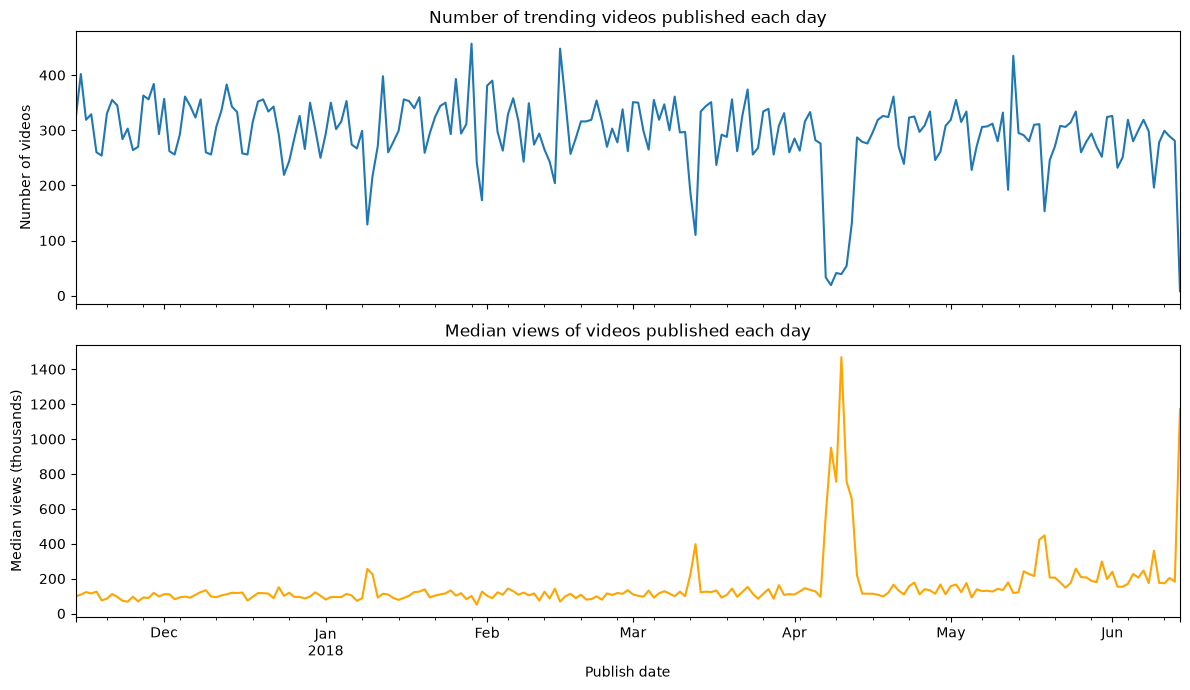

In [85]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

daily_df['count'].plot(ax=axes[0])
axes[0].set_title('Number of trending videos published each day')
axes[0].set_ylabel('Number of videos')

(daily_df['median'] / 1000).plot(ax=axes[1], color='orange')
axes[1].set_title('Median views of videos published each day')
axes[1].set_ylabel('Median views (thousands)')
axes[1].set_xlabel('Publish date')

plt.tight_layout()
plt.savefig('charts/daily_publish_and_views.png', bbox_inches='tight')
plt.show()

- Most days had about **250 to 350** new trending videos.
- The big drop in early April matches the missing trending dates (April 8 to 13), so it is a gap in the data, not fewer uploads.
- Median views stayed around **100,000** until March 2018, then rose to around **200,000** by June. The data does not tell us why.

#### 6. Do busy publish days have higher or lower views?

Each dot is one publish date.

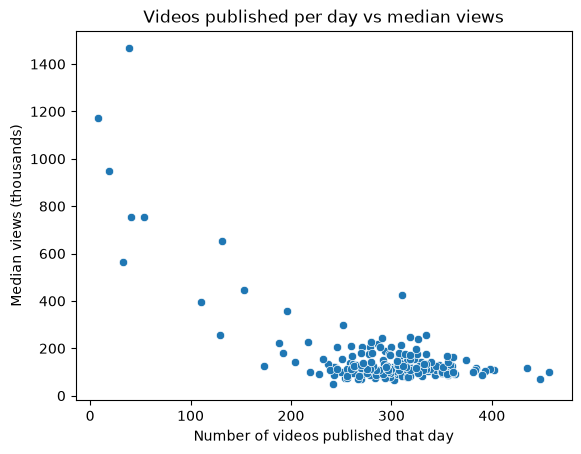

In [86]:
sns.scatterplot(x=daily_df['count'], y=daily_df['median'] / 1000)
plt.title('Videos published per day vs median views')
plt.xlabel('Number of videos published that day')
plt.ylabel('Median views (thousands)')
plt.show()

Most dots sit in one group: **250 to 350 videos** and **100,000 to 200,000** median views. The few dots on the left with very high views are April 7 to 11 and June 14, right next to the data gaps and the end of the data. Without them there is **no clear pattern**, so we cannot say that publishing on a quieter day leads to more views.

## Part 7: Summary and recommendations

| # | Topic | Result |
| --- | --- | --- |
| 1 | Views and likes | Fairly strong relationship (**0.71**). More views usually means more likes. |
| 2 | Views and comments | Weaker relationship (**0.53**). Likes and comments are strongly linked (**0.82**). |
| 3 | Typical engagement | About **2.75 likes** and **0.38 comments** per 100 views. |
| 4 | Uneven views | Median of about **124,500** views on the first trending day, while a few had tens of millions. |
| 5 | Timing | About **77%** of videos trended one day after publishing. Median views doubled between March and June 2018. |
| 6 | Busy days | No clear link between how many videos were published on a day and their views. |
| 7 | Countries | France has the most videos and the lowest median views. |

### Example: what is a normal number of likes?

This chart is **an example, not a prediction**.

We take a video that reaches the trending list with **124,496 views** (the median in our data) and multiply by the real likes per 100 views from Part 5:

- **Low:** a video in the bottom 25% (`quantile(0.25)`)
- **Typical:** the median
- **High:** a video in the top 25% (`quantile(0.75)`)

In [87]:
example_views = newyoutube_df['views'].median()

low_rate = engagement_df['likes_per_100_views'].quantile(0.25)
typical_rate = engagement_df['likes_per_100_views'].median()
high_rate = engagement_df['likes_per_100_views'].quantile(0.75)

scenario = pd.Series({
    'Low (bottom 25%)': example_views * low_rate / 100,
    'Typical (median)': example_views * typical_rate / 100,
    'High (top 25%)': example_views * high_rate / 100,
})
scenario.round()

Low (bottom 25%)    1172.0
Typical (median)    3422.0
High (top 25%)      7569.0
dtype: float64

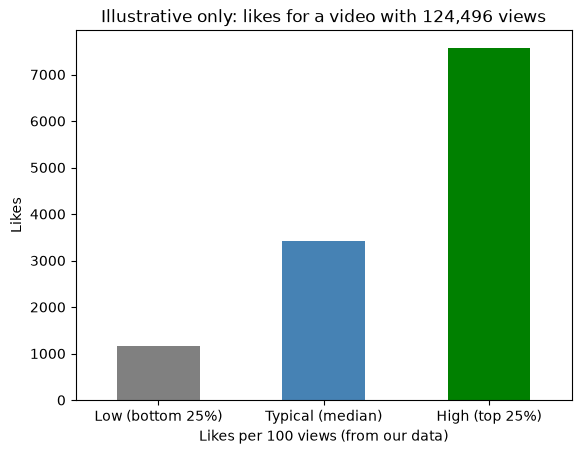

In [88]:
scenario.plot(kind='bar', rot=0, color=['grey', 'steelblue', 'green'])
plt.title('Illustrative only: likes for a video with 124,496 views')
plt.xlabel('Likes per 100 views (from our data)')
plt.ylabel('Likes')
plt.savefig('charts/illustrative_likes_scenario.png', bbox_inches='tight')
plt.show()

With the same views, a video could have about **1,200** likes (low), **3,400** likes (typical), or **7,600** likes (high). Two trending videos with the same views can have very different engagement, which matches the spread we saw in Part 5.

### Recommendations

1. **Compare engagement using likes per 100 views,** not raw likes. About 1 to 6 likes per 100 views is normal for trending videos in this data.
2. **Check likes and comments in the first day or two** after publishing, because most videos reached the trending list the next day.
3. **Use medians, not averages,** when describing views, because a few huge videos pull the average up.
4. **Look at each country separately,** because France has many more videos with lower views.
5. **Do not pick a "best day" to publish** from this data. We found no clear pattern between busy publish days and views.

### Limitations

- We removed **2,016 rows (1.25%)**: 1,799 with a `#NAME?` video ID and 219 exact duplicates.
- We only kept the first trending day per video and country, so we do not see how views grew after that.
- Trending data is missing for January 10 to 11 and April 8 to 13, 2018.
- The data covers only four countries from November 2017 to June 2018, so it does not represent all YouTube videos.
- All results are relationships. They do not show that likes, comments, or publish dates cause more views.